# 10 · BEV + side, no front view: a two-plane TPV from reused perspective features

**`TRIPLANE_LIFTERS["bev_side"]` → `lifting.triplane.BEVSideTriplaneLifter`**  ·  two-plane variant of the
tri-perspective view (Huang et al., *TPVFormer*, 2023)

> Read the cameras **once** into a voxel volume, then pool that same volume twice - over height for the BEV
> plane, over the lateral axis for the side plane - and let the two planes talk along the forward axis they
> share. The `yz` front plane is never built.

A TPV stores a scene as three planes `xy` (BEV), `xz` (side) and `yz` (front). Two questions motivate this
variant:

1. **Is the front plane needed?** With `xy(x, y) + xz(x, z)` every voxel is still addressed on all three axes:
   `x` by both planes, `y` by the BEV plane, `z` by the side plane. What is lost is the `(y, z)` coupling that
   does not go through `x`.
2. **Do the planes need separate camera passes?** `bevformer` / `tpvformer` run one image cross-attention per
   plane. Here the perspective (camera) features are sampled once into a voxel volume, and both planes are
   *pooled from that same volume* - the image access is shared.

This notebook builds the lifter, checks every intermediate tensor, and measures what dropping the front plane
costs on the toy occupancy task, next to the three-plane `simple_bev` and `tpvformer`.

## 1. The idea

![BEV + side triplane lifting animation](../../assets/triplane/bev_side.gif)

### Detailed diagram

```mermaid
flowchart LR
  IMG["N camera images<br/>(B, N, 3, H, W)"]:::data --> ENC["ImageEncoder<br/>pyramid (B, N, C, H_l, W_l)"]:::learned
  CAM["Cameras<br/>K · cam_to_ego"]:::data
  subgraph VOL["volume lifter (existing, reused): simple_bev | depth_warp | lift_splat | tiim"]
    direction TB
    LV["lift_voxels<br/>project · read · camera mean"]:::reused
  end
  ENC --> LV
  CAM --> LV
  LV --> V["perspective volume V<br/>(B, C, X, Y, Z)<br/>the ONLY camera access"]:::reused
  V --> PH["AxisAttentionPool over Z<br/>(pool_height)"]:::learned
  V --> PL["AxisAttentionPool over Y<br/>(pool_lateral)"]:::learned
  PH --> XY["xy (B, C, X, Y)"]:::out
  PL --> XZ["xz (B, C, X, Z)"]:::out
  XY <--> MIX["BEVSideMixer × L<br/>row-wise cross-attention along x"]:::learned
  XZ <--> MIX
  MIX --> TPV["TPVPlanes(xy, xz, yz=None)"]:::out
  TPV --> BEVH["TriplaneBEVHead<br/>f = xy + xz → fold Z → BEV"]:::learned
  TPV --> AGG["TPVAggregator<br/>voxel + point logits"]:::learned
  classDef data fill:#fff7e6,stroke:#d48806,color:#222
  classDef geo fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef learned fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef reused fill:#eaf7ea,stroke:#2e8b57,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

### Shapes and equations

With the shared volume $V \in \mathbb{R}^{C \times X \times Y \times Z}$ (from `volume.lift_voxels`):

$$ xy[:, x, y] = W_o \sum_{z} \alpha^{(h)}_{x,y,z}\, W_v\big(V[:, x, y, z] + E^Z_z\big), \qquad
   \alpha^{(h)}_{x,y,\cdot} = \mathrm{softmax}_z\, w_h^\top\big(V[:, x, y, \cdot] + E^Z\big) $$

$$ xz[:, x, z] = W'_o \sum_{y} \beta^{(h)}_{x,z,y}\, W'_v\big(V[:, x, y, z] + E^Y_y\big) $$

($h$ = head, $E$ = learned position embeddings along the pooled axis). A mixer layer, for each row $x$:

$$ xy_x \leftarrow xy_x + \mathrm{Attn}(xy_x + P^Y,\ xz_x + P^Z,\ xz_x), \qquad
   xz_x \leftarrow xz_x + \mathrm{Attn}(xz_x + P^Z,\ xy_x + P^Y,\ xy_x) $$

followed by a depthwise-3×3 FFN per plane. Decoding: $f(x, y, z) = xy(x, y) + xz(x, z)$.

| tensor | shape |
|---|---|
| features (level 0) | `(B, N, C, H/4, W/4)` |
| shared volume `V` | `(B, C, X, Y, Z)` |
| `xy` / `xz` | `(B, C, X, Y)` / `(B, C, X, Z)` |
| `yz` | `None` |
| plane cells | `X·Y + X·Z` (vs `X·Y + X·Z + Y·Z` for a TPV) |

In [1]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")

# tpv_kit lives next to this notebook; also works when Jupyter starts at the repo root.
for _p in (".", os.path.join("notebooks", "triplane")):
    if os.path.isdir(os.path.join(_p, "tpv_kit")):
        sys.path.insert(0, os.path.abspath(_p)); break

import numpy as np
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt

from lifting import BaseLifter
from lifting.encoders import SimpleConvEncoder
from lifting.lifters import TPVPlanes
from lifting.triplane import (TRIPLANE_LIFTERS, BEVSideTriplaneLifter, VoxelVolumeSource,
                              build_triplane_lifter, build_triplane_model, build_triplane_bev_model)
from tpv_kit import (TriplaneScene, PlanePlotter, PipelineDiagram, StoryboardViewer,
                     TriplaneContractChecker, OccupancyExperiment, ExperimentResult)

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams.update({"figure.dpi": 100, "image.interpolation": "nearest"})
plotter = PlanePlotter()
print("torch", torch.__version__, "| triplane lifters:", TRIPLANE_LIFTERS.names())

torch 2.14.1 | triplane lifters: ['alpamayo', 'bev_adapter', 'bev_side', 'bevformer', 'depth_warp', 'lift_splat', 'mlp_view', 'simple_bev', 'tiim', 'tpvformer']


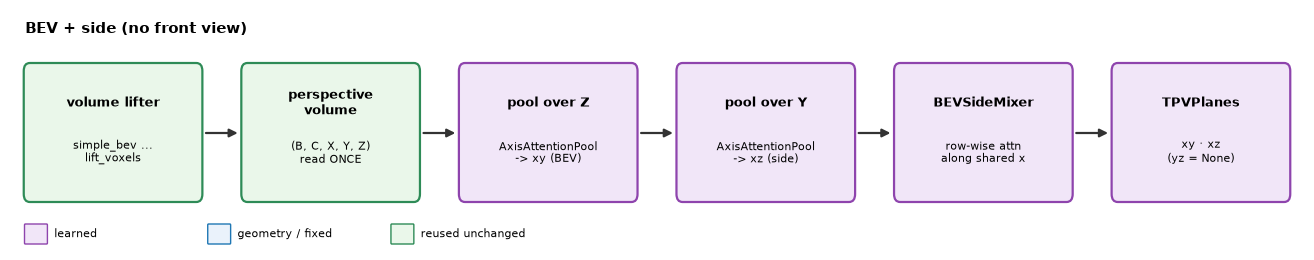

In [2]:
PipelineDiagram('BEV + side (no front view)').extend([
    ('volume lifter', 'simple_bev ...\nlift_voxels', 'reused'),
    ('perspective\nvolume', '(B, C, X, Y, Z)\nread ONCE', 'reused'),
    ('pool over Z', 'AxisAttentionPool\n-> xy (BEV)', 'learned'),
    ('pool over Y', 'AxisAttentionPool\n-> xz (side)', 'learned'),
    ('BEVSideMixer', 'row-wise attn\nalong shared x', 'learned'),
    ('TPVPlanes', 'xy · xz\n(yz = None)', 'learned'),
]).show()

## 2. The animation, one still per step

The same toy scene as every other triplane notebook. The front plane is drawn crossed out ("not computed"):
the technique never builds it. Regenerate with `python scripts/make_triplane_gifs.py --only bev_side`.

step 1: Inputs
step 2: Voxel centres
step 3: Project into every camera
step 4: Sample the perspective features ONCE
step 5: Reuse the volume twice
step 6: BEV <-> side mixing along x
step 7: Triplane output


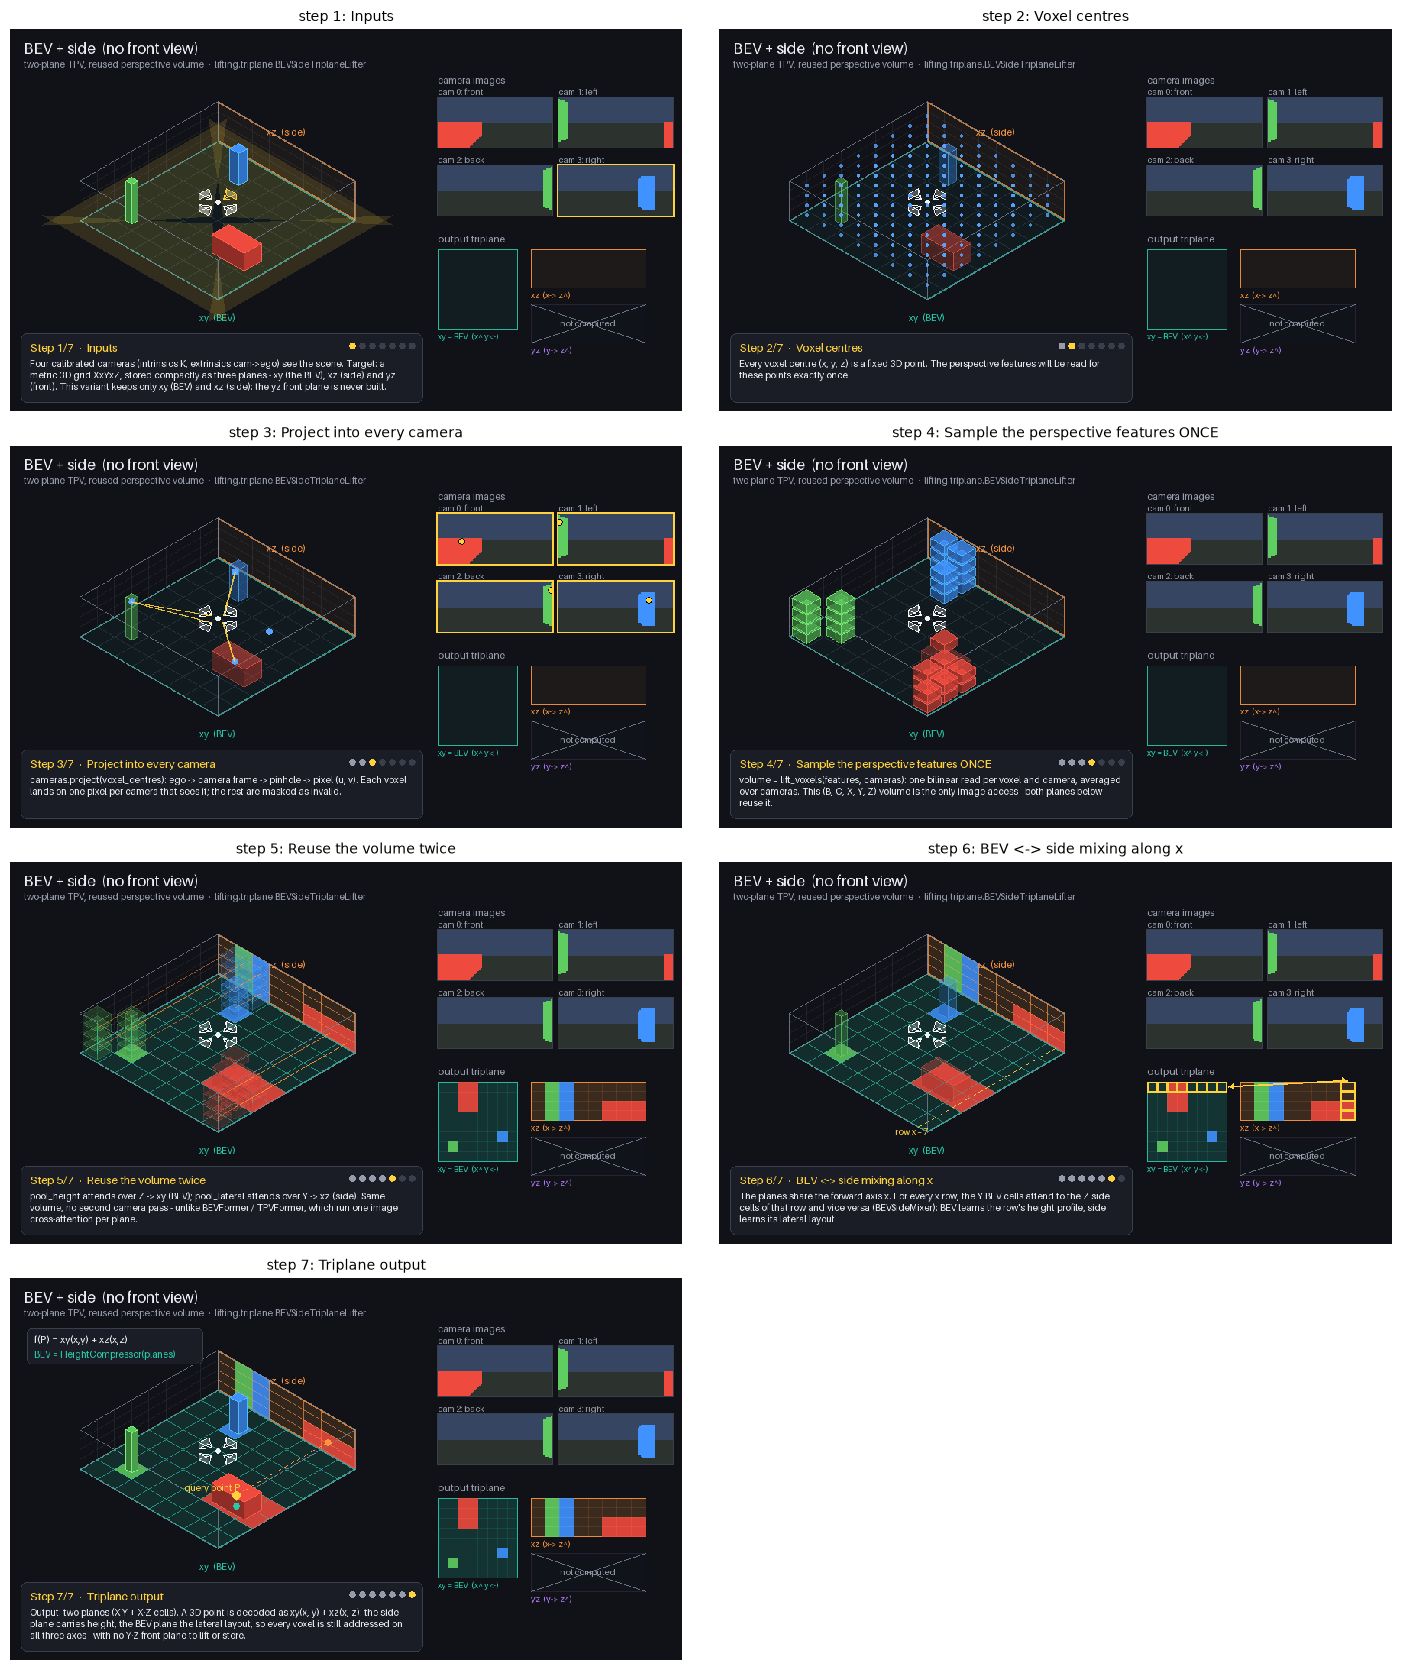

In [3]:
viewer = StoryboardViewer("bev_side")
for i, title in enumerate(viewer.step_titles(), 1):
    print(f"step {i}: {title}")
viewer.contact_sheet()

## 3. The scene

`32 m × 32 m × 4 m` cut into `16 × 16 × 4` cells, four randomly yawed `48 × 96` cameras per scene,
vehicles (red) and pedestrians (blue). The label planes are the 3D occupancy collapsed along each axis; this
lifter is supervised on the `xy` and `xz` ones only.

grid      : x (-16.0, 16.0) y (-16.0, 16.0) z (-1.0, 3.0) m, resolution (16, 16, 4)
voxel     : (2.0, 2.0, 1.0) m
cameras   : 4 x (48, 96) px
scenes    : 128 train / 32 test (batch 4)
TPV cells : xy 256 + xz 64 + yz 64 = 384  (voxels: 1024)


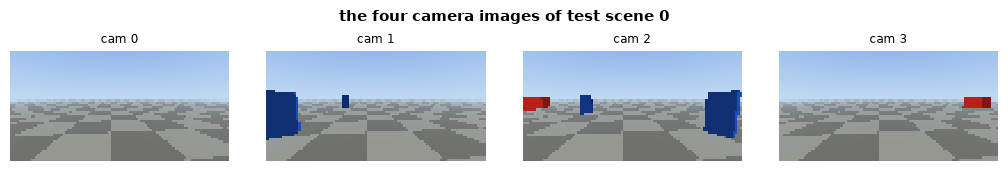

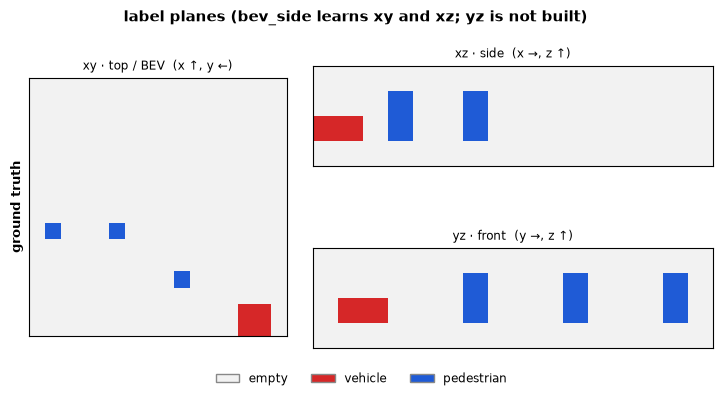

In [4]:
scene = TriplaneScene()
print(scene.describe())
batch = scene.sample
plotter.cameras(batch.images, title="the four camera images of test scene 0")
plotter.labels([("ground truth", scene.label_planes(batch.occupancy))],
               title="label planes (bev_side learns xy and xz; yz is not built)")

## 4. Build the lifter

`build_triplane_lifter("bev_side", ...)` forwards the build context (`feature_size`, `num_cameras`,
`depth_bins`) to the **volume** lifter, so any voxel-volume source can be chosen with `volume=`.
The source's own plane compressors and BEV head are dropped: only its `lift_voxels` is reused.

In [5]:
C = 32
encoder = SimpleConvEncoder(out_channels=C, num_levels=2)
features = scene.encode(encoder, batch)
cameras = batch.cameras

lifter = build_triplane_lifter("bev_side", scene.grid, C, scene.image_size, scene.num_cameras, encoder)
print(type(lifter).__name__, "| planes:", lifter.planes, "| is a BaseLifter:", isinstance(lifter, BaseLifter))
print("volume source:", lifter.volume_name, "->", type(lifter.volume).__name__,
      "| satisfies VoxelVolumeSource:", isinstance(lifter.volume, VoxelVolumeSource))
print(f"parameters: {sum(p.numel() for p in lifter.parameters()):,}")
for name, child in lifter.named_children():
    n = sum(p.numel() for p in child.parameters())
    print(f"  .{name:<13s} {type(child).__name__:<28s} {n:>9,} params")

BEVSideTriplaneLifter | planes: ('xy', 'xz') | is a BaseLifter: True
volume source: simple_bev -> SimpleBEVTriplaneLifter | satisfies VoxelVolumeSource: True
parameters: 79,592
  .bev_head      TriplaneBEVHead                 37,984 params
  .volume        SimpleBEVTriplaneLifter              0 params
  .pool_height   AxisAttentionPool                2,372 params
  .pool_lateral  AxisAttentionPool                2,756 params
  .mixers        ModuleList                      36,480 params


## 5. Inside the lifter, step by step

### 5.1 The perspective features are sampled exactly once

We wrap `volume.lift_voxels` with a counter and run `lift_planes`: the cameras are read one time, and both
planes get their gradient from that single volume.

In [6]:
calls = []
original = lifter.volume.lift_voxels
def counted(*args, **kwargs):
    out = original(*args, **kwargs)
    calls.append(out)
    return out
lifter.volume.lift_voxels = counted
feats = [f.detach().requires_grad_() for f in features]
planes = lifter.lift_planes(feats, cameras)
lifter.volume.lift_voxels = original
print("camera passes (lift_voxels calls):", len(calls))
volume = calls[0]
volume.retain_grad()
g_xy = torch.autograd.grad(planes.xy.square().mean(), volume, retain_graph=True)[0]
g_xz = torch.autograd.grad(planes.xz.square().mean(), volume)[0]
print("volume", tuple(volume.shape), "| d xy / d V nonzero:", bool(g_xy.abs().sum() > 0),
      "| d xz / d V nonzero:", bool(g_xz.abs().sum() > 0))
print("planes:", {name: tuple(p.shape) for name, p in planes.items()}, "| yz:", planes.yz)

camera passes (lift_voxels calls): 1
volume (4, 32, 16, 16, 4) | d xy / d V nonzero: True | d xz / d V nonzero: True
planes: {'xy': (4, 32, 16, 16), 'xz': (4, 32, 16, 4)} | yz: None


### 5.2 Pool the same volume twice: `AxisAttentionPool`

`pool_height` collapses `Z` (each BEV pillar chooses which heights matter); `pool_lateral` collapses `Y`
(each side-plane line chooses which lateral positions matter). The cell recomputes one BEV cell by hand
from `last_weights` and checks the library's value.

In [7]:
with torch.no_grad():
    V = lifter.lift_volume(features, cameras)
    pool = lifter.pool_height
    xy = pool(V)
    w = pool.last_weights                                 # (B, heads, X, Y, Z)
    b, x, y = 0, 5, 7
    Vp = V + pool.position[None, :, None, None, :]
    values = pool.value(Vp)[b, :, x, y]                  # (C, Z)
    heads = pool.num_heads
    pooled = (values.view(heads, -1, values.shape[-1]) * w[b, :, x, y][:, None]).sum(-1).reshape(-1)
    by_hand = pool.output.weight[..., 0, 0] @ pooled + pool.output.bias
print("attention weights sum to 1 over Z:", torch.allclose(w.sum(-1), torch.ones_like(w.sum(-1))))
print("BEV cell (5, 7) by hand == library:", torch.allclose(by_hand, xy[b, :, x, y], atol=1e-5))
print("side plane from the SAME volume:", tuple(lifter.pool_lateral(V.permute(0, 1, 2, 4, 3)).shape))

attention weights sum to 1 over Z: True
BEV cell (5, 7) by hand == library: True
side plane from the SAME volume: (4, 32, 16, 4)


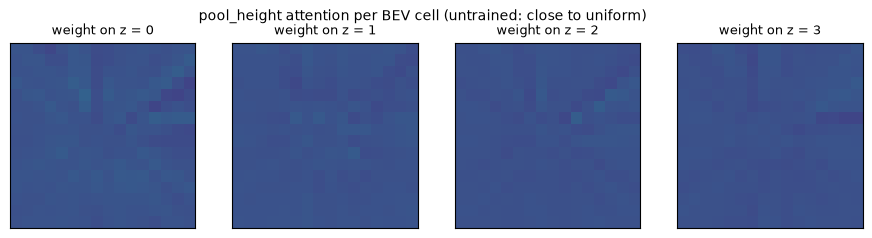

In [8]:
# Where along height does each BEV pillar look? (head-averaged attention, untrained lifter)
att = w[0].mean(0)                                        # (X, Y, Z)
fig, axes = plt.subplots(1, att.shape[-1], figsize=(11, 2.6))
for z, ax in enumerate(axes):
    ax.imshow(att[..., z].numpy(), vmin=0, vmax=1, cmap="viridis"); ax.set_title(f"weight on z = {z}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("pool_height attention per BEV cell (untrained: close to uniform)", fontsize=10); plt.show()

### 5.3 BEV ↔ side mixing along the shared `x` axis

The planes share only `x`. `BEVSideMixer` treats every `x` row as a short sequence: the `Y` BEV cells of that
row attend to its `Z` side cells and vice versa. The cell verifies that the side row `x = 3` reads the BEV row
`x = 3` (gradient) - and, before the FFN's depthwise convolution, nothing else.

In [9]:
mixer = lifter.mixers[0]
with torch.no_grad():
    bev0 = lifter.pool_height(V)
    side0 = lifter.pool_lateral(V.permute(0, 1, 2, 4, 3))
bev_in, side_in = bev0.clone().requires_grad_(), side0.clone().requires_grad_()
rows_b, rows_s = mixer._rows(bev_in), mixer._rows(side_in)
nb, ns = mixer.norm_bev(rows_b), mixer.norm_side(rows_s)
qs = ns + mixer.pos_z[: ns.shape[1]]
qb = nb + mixer.pos_y[: nb.shape[1]]
side_attn = mixer.side_reads_bev(qs, qb, nb, need_weights=False)[0]   # attention part only
side_attn = mixer._plane(side_attn, bev_in.shape[0], bev_in.shape[2])
side_attn[:, :, 3].sum().backward()
touched = (bev_in.grad.abs().sum(dim=(0, 1, 3)) > 0).nonzero().flatten().tolist()
print("side row x=3 reads BEV rows:", touched)

side row x=3 reads BEV rows: [3]


### 5.4 Two planes, fewer cells

Without the `Y·Z` front plane the representation is smaller; the voxel feature is `xy + xz`.

In [10]:
with torch.no_grad():
    planes = lifter.lift_planes(features, cameras)
nx, ny, nz = scene.grid.resolution
two = sum(p[0].numel() for p in planes.tensors())
three = two + C * ny * nz
print(f"plane floats per scene: bev_side {two:,} vs three-plane TPV {three:,} "
      f"(-{100 * (1 - two / three):.0f}%) vs voxels {C * nx * ny * nz:,}")
vox = planes.to_voxels()
i, j, k = 4, 9, 2
print("f(4, 9, 2) == xy(4, 9) + xz(4, 2):",
      torch.allclose(vox[0, :, i, j, k], planes.xy[0, :, i, j] + planes.xz[0, :, i, k]))

plane floats per scene: bev_side 10,240 vs three-plane TPV 12,288 (-17%) vs voxels 32,768
f(4, 9, 2) == xy(4, 9) + xz(4, 2): True


## 6. The triplane contract, verified

`TriplaneContractChecker` knows two-plane lifters: it expects exactly `lifter.planes`, checks
`f = xy + xz` and that the reused volume comes from a registered triplane lifter.

PASS  plane shapes            xy(4, 32, 16, 16) xz(4, 32, 16, 4) (no yz: two-plane TPV)
PASS  BEV = bev_head(planes)  BEV (4, 32, 16, 16), max |diff| = 0.0e+00
PASS  f = xy + xz             voxel (8,8,2) max |diff| = 0.0e+00
PASS  reuses a voxel volume   volume = SimpleBEVTriplaneLifter = TRIPLANE_LIFTERS['simple_bev']
PASS  gradients reach images  1/2 pyramid levels receive gradient


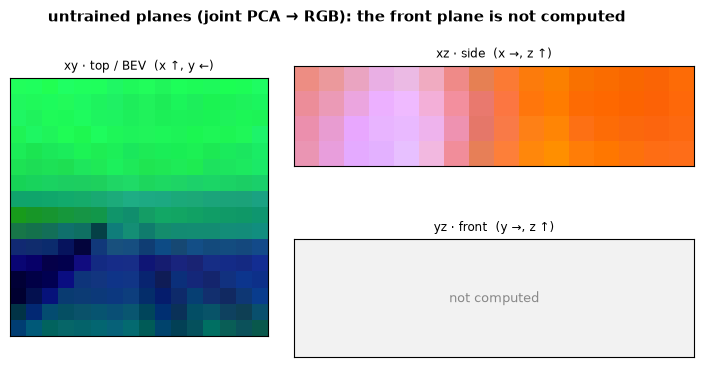

In [11]:
assert TriplaneContractChecker(lifter, features, cameras).run()
with torch.no_grad():
    planes = lifter.lift_planes(features, cameras)
plotter.features(planes, title="untrained planes (joint PCA → RGB): the front plane is not computed")

## 7. Train end to end on 3D semantic occupancy

`build_triplane_model("bev_side", ...)` = encoder → this lifter → `TPVAggregator` on `xy + xz`, with aux heads
on `xy` and `xz` (the `yz` slot is a parameter-free placeholder). 150 AdamW steps, CPU.

lifter          params    time   before    after  corrupted   verdict
bev_side          212k   10.5s    0.000    0.331      0.031   uses geometry


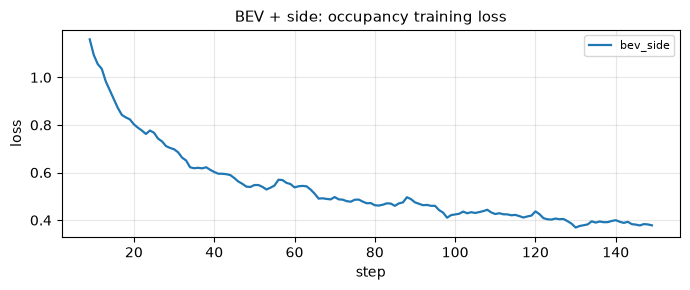

In [12]:
exp = OccupancyExperiment(scene, "bev_side")
result = exp.run(steps=150)
print(ExperimentResult.header()); print(result.row())
OccupancyExperiment.plot_losses([result], title="BEV + side: occupancy training loss")

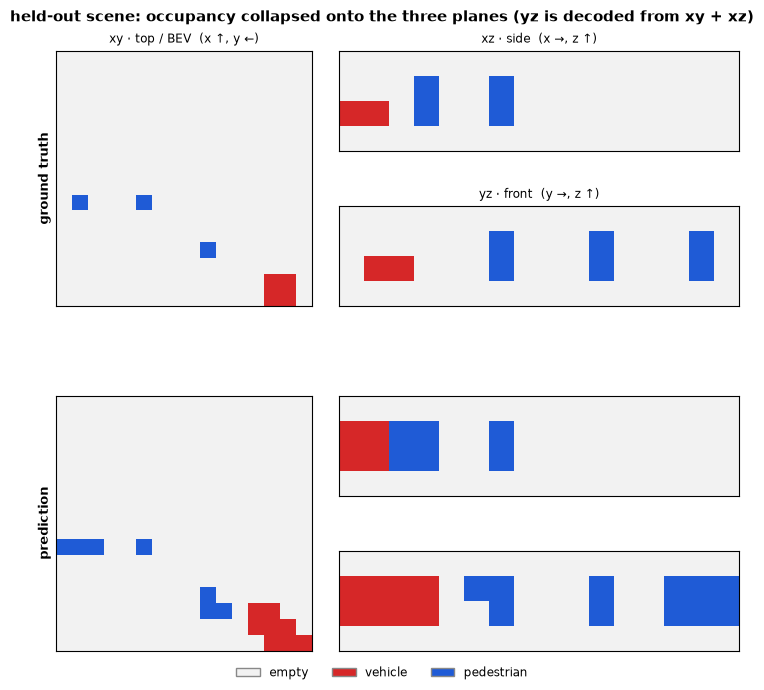

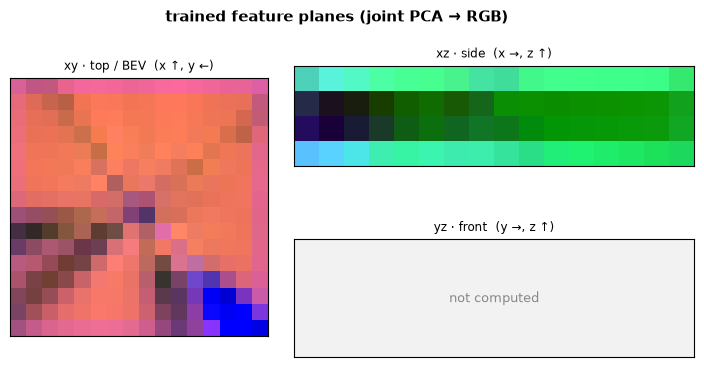

In [13]:
out = exp.predict()
pred = out["voxel_logits"].argmax(1)
plotter.labels([("ground truth", scene.label_planes(batch.occupancy)),
                ("prediction", scene.label_planes(pred))],
               title="held-out scene: occupancy collapsed onto the three planes (yz is decoded from xy + xz)")
plotter.features(out["planes"], title="trained feature planes (joint PCA → RGB)")

Note that the **predicted** `yz` label plane above is still meaningful: the voxels are decoded from
`xy + xz`, and collapsing them along `x` gives a front view - the front plane is not stored, but the front
*view* of the prediction is still available.

## 8. Negative control: does it really use the cameras?

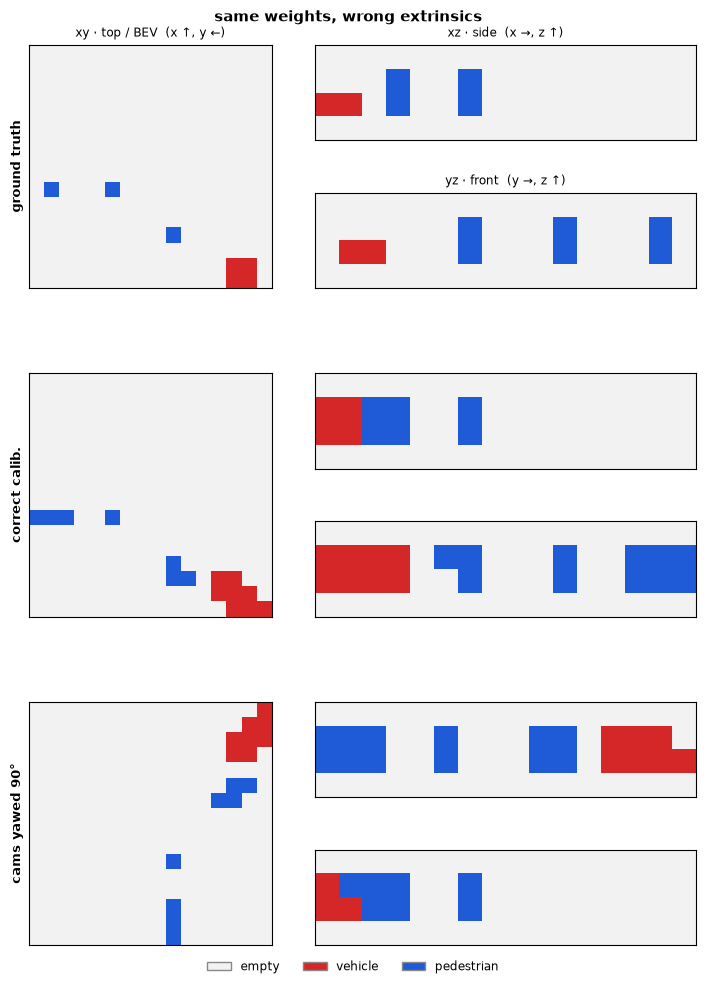

mIoU  correct calibration: 0.331   |   cameras yawed 90°: 0.031   ->  uses geometry ✅


In [14]:
corrupted = exp.predict(corrupted=True)["voxel_logits"].argmax(1)
plotter.labels([("ground truth", scene.label_planes(batch.occupancy)),
                ("correct calib.", scene.label_planes(pred)),
                ("cams yawed 90°", scene.label_planes(corrupted))],
               title="same weights, wrong extrinsics")
print(f"mIoU  correct calibration: {result.miou_after:.3f}   |   cameras yawed 90°: {result.miou_corrupted:.3f}"
      f"   ->  {'uses geometry ✅' if result.uses_geometry else 'does NOT use geometry'}")

## 9. What does dropping the front plane cost? Head-to-head

Same scene, same 150 steps, two seeds each:

* `simple_bev`: three planes folded from the same kind of volume;
* `tpvformer`: three planes, one image cross-attention per plane;
* `bev_side` and its ablations: no mixing (`mix_layers=0`), channel folding instead of attention pooling
  (`pooling="fold"`), and a depth-aware volume (`volume="lift_splat"`).

In [15]:
runs = [("simple_bev", {}), ("tpvformer", {"num_layers": 1}),
        ("bev_side", {}), ("bev_side", {"mix_layers": 0}), ("bev_side", {"pooling": "fold"}),
        ("bev_side", {"volume": "lift_splat"})]
table = []
for name, kw in runs:
    scores, seconds, params = [], [], 0
    for seed in (0, 1):
        e = OccupancyExperiment(scene, name, seed=seed, **kw)
        lifter_params = sum(p.numel() for p in e.model.lifter.parameters() if p.requires_grad)
        r = e.run(steps=150)
        scores.append(r.miou_after); seconds.append(r.seconds)
    label = name + ("" if not kw else " (" + ", ".join(f"{k}={v}" for k, v in kw.items()) + ")")
    table.append((label, lifter_params, np.mean(scores), np.std(scores), np.mean(seconds)))
print(f"{'lifter':42s} {'lifter params':>13s} {'mIoU (2 seeds)':>16s} {'train s':>8s}")
for label, p, m, s, sec in table:
    print(f"{label:42s} {p / 1e3:12.0f}k {m:9.3f} ± {s:.3f} {sec:8.1f}")

lifter                                     lifter params   mIoU (2 seeds)  train s
simple_bev                                          335k     0.371 ± 0.004      8.3
tpvformer (num_layers=1)                             61k     0.334 ± 0.010      9.8
bev_side                                             42k     0.345 ± 0.014      7.0
bev_side (mix_layers=0)                               5k     0.359 ± 0.013      3.7
bev_side (pooling=fold)                             223k     0.356 ± 0.011      5.9
bev_side (volume=lift_splat)                         53k     0.282 ± 0.008      9.4


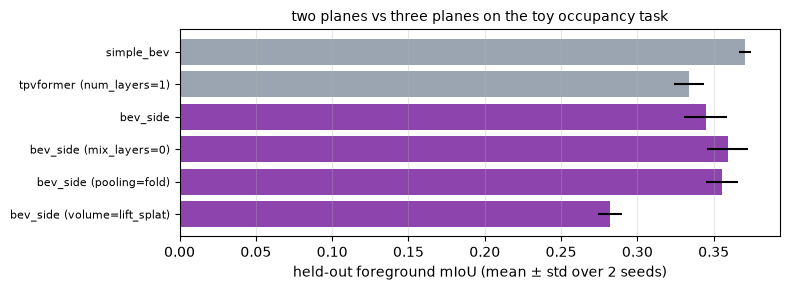

In [16]:
fig, ax = plt.subplots(figsize=(8, 3))
labels = [t[0] for t in table]
ax.barh(range(len(table)), [t[2] for t in table], xerr=[t[3] for t in table],
        color=["#9aa5b1" if not l.startswith("bev_side") else "#8e44ad" for l in labels])
ax.set_yticks(range(len(table)), labels, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("held-out foreground mIoU (mean ± std over 2 seeds)")
ax.set_title("two planes vs three planes on the toy occupancy task", fontsize=10)
ax.grid(axis="x", alpha=0.3); plt.tight_layout(); plt.show()

## 10. Use it in your own code

```python
from lifting.triplane import TRIPLANE_LIFTERS, build_triplane_model, build_triplane_bev_model

lifter = TRIPLANE_LIFTERS.build("bev_side", grid=grid, in_channels=64, out_channels=64,
                                volume="lift_splat", pooling="attention", mix_layers=2)
planes = lifter.lift_planes(features, cameras)   # TPVPlanes(xy, xz, yz=None)
volume = lifter.lift_volume(features, cameras)   # the shared perspective volume
planes = lifter.planes_from_volume(volume)       # re-pool without touching the cameras
bev = lifter(features, cameras)                  # (B, 64, X, Y) - drop-in BEV lifter

model = build_triplane_model("bev_side", grid, num_classes=3, aux_heads=True)
out = model(images, cameras, points=lidar_xyz)   # voxel / point logits decoded from xy + xz
```

In [17]:
bev_model = build_triplane_bev_model("bev_side", scene.grid, 3, scene.image_size, scene.num_cameras, channels=16)
with torch.no_grad():
    logits = bev_model(batch.images, batch.cameras)["logits"]
print("BEV segmentation logits read off the two planes:", tuple(logits.shape))

BEV segmentation logits read off the two planes: (4, 3, 16, 16)


## Recap

* `bev_side` keeps the BEV (`xy`) and side (`xz`) planes and drops the front (`yz`) plane:
  `X·Y + X·Z` cells, and `f = xy + xz` still addresses every voxel on all three axes.
* The perspective features are read **once** (any `VoxelVolumeSource`: `simple_bev`, `depth_warp`,
  `lift_splat`, `tiim`) and both planes are pooled from that same volume.
* `AxisAttentionPool` reduces an axis with content-dependent attention and position embeddings;
  `BEVSideMixer` couples the planes along the `x` axis they share.
* `TPVPlanes.yz` is optional across the library: BEV head, aggregator, point queries, aux heads and the
  occupancy loss all work with two planes.

**Cheat sheet**

| concept | file |
|---|---|
| the lifter | `src/lifting/triplane/bev_side_triplane.py` |
| axis attention pooling | `src/lifting/triplane/axis_attention_pool.py` |
| BEV ↔ side mixer | `src/lifting/triplane/bev_side_mixer.py` |
| reusable volume protocol | `src/lifting/triplane/voxel_volume_source.py` |
| optional front plane | `src/lifting/lifters/tpvformer/tpv_planes.py` |
| this animation | `src/lifting/triplane/animation/storyboards/bev_side_storyboard.py` |
| tests | `tests/unit/triplane/test_bev_side.py` |

**Exercises**

1. Increase `Z` to 8 (`TriplaneScene(resolution=(16, 16, 8))`): does the side plane's share of the work grow?
2. Train with `mix_layers=4`. When does mixing stop helping?
3. Swap the roles: build a BEV + front (`xy`, `yz`) lifter by pooling over `X` instead of `Y` - which of the two
   is better for a forward-facing rig?

Next: `00_triplane_overview.ipynb` for all techniques side by side.